# 11 — SOLETE retrospective evaluation

## Purpose

This notebook evaluates the feature representations developed in Notebooks 05–08 on the **June–August 2019 SOLETE period**. It fits the same fixed LightGBM configuration to each representation, scores the same forecast-valid timestamps, and compares the errors at 15-, 30-, and 60-minute horizons.

The evaluation includes F0–F4, two continuous-sidereal controls, the previously selected development models, and the two persistence baselines. We report all-hours and daylight results with paired uncertainty intervals.

This evaluation is **retrospective**: the June–August 2019 SOLETE period had been inspected during earlier research. Accordingly, these results describe the performance of the specified forecasting representations rather than an independent confirmation on previously untouched data.

## 1. Forecasting design

The target is SOLETE photovoltaic power (`P_Solar[kW]`) at forecast-valid time \(v=t+h\). Historical measurements are selected at the issue time \(t\) or earlier. Calendar, solar, lunar and Panchang predictors are selected at \(v\).

Every model uses **LightGBM C1**: 300 trees, learning rate 0.03, 15 leaves and the frozen parameters in `src/classical_models.py`. The previously selected development reference is **F1 for 15 minutes** and **F2 for 30 and 60 minutes**.

The paired comparisons use the same eligible timestamps, the same development training-label cutoff, and the same model settings for every representation. The split definitions are those established in Notebook 05.

In [1]:
from pathlib import Path
import gc
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / 'solete_dataset' / 'SOLETE_Pombo_5min.h5').is_file()
        and (p / 'src' / 'forecasting_protocol.py').is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the SOLETE project.')
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_solete
from src.preprocessing import build_cleaned_solete_features, build_gregorian_features
from src.astronomy_features import (
    build_lunar_f3_features,
    build_solar_f2_features,
    load_jpl_ephemeris,
    solete_astronomy_reference_times,
    tropical_longitudes_for_solete,
)
from src.vedic_calendar import (
    build_panchang_f4_raw,
    lahiri_ayanamsha_for_utc_times,
    sidereal_longitude_from_tropical,
    yoga_angle_from_tropical_longitudes,
)
from src.feature_families import (
    FEATURE_FAMILY_COUNTS,
    encode_panchang_fixed_vocabulary,
)
from src.forecasting_protocol import (
    FORECAST_HORIZONS,
    EXPECTED_TERMINAL_REFIT_COUNTS_BY_HORIZON,
    TEST_START,
    TEST_END,
    build_f0_history,
    build_forecast_targets,
    build_base_modelling_tables,
    make_terminal_refit_mask,
    terminal_holdout_mask,
    validate_solete_5min_index,
)
from src.classical_models import build_lightgbm_model

HORIZONS = (15, 30, 60)
MODEL_CONFIG = {'n_estimators': 300, 'learning_rate': 0.03, 'num_leaves': 15}
FEATURE_NAMES = ('F0', 'F1', 'F2', 'F3', 'F4', 'F3_sidereal', 'F4_sidereal')
SELECTED_REFERENCE = {15: 'F1', 30: 'F2', 60: 'F2'}
DIMENSIONS = {
    'F0': 118, 'F1': 133, 'F2': 138, 'F3': 147, 'F4': 244,
    'F3_sidereal': 151, 'F4_sidereal': 248,
}
assert HORIZONS == tuple(FORECAST_HORIZONS)
assert FEATURE_FAMILY_COUNTS == {k: DIMENSIONS[k] for k in ('F0', 'F1', 'F2', 'F3', 'F4')}

print('Forecast horizons (minutes):', HORIZONS)
print('Selected development references:', SELECTED_REFERENCE)
print('Fixed LightGBM configuration:', MODEL_CONFIG)

Forecast horizons (minutes): (15, 30, 60)
Selected development references: {15: 'F1', 30: 'F2', 60: 'F2'}
Fixed LightGBM configuration: {'n_estimators': 300, 'learning_rate': 0.03, 'num_leaves': 15}


## 2. Prepare the observational samples

We reconstruct the same SOLETE 5-minute observational history used for development. The 118 F0 predictors include recent PV, irradiance and weather measurements, together with the previous-day PV value.

Development refitting uses target labels available before the earliest retrospective forecast issue time. Each horizon has **26,496** retrospective forecast-valid samples.

In [2]:
DATA_FILE = PROJECT_ROOT / 'solete_dataset' / 'SOLETE_Pombo_5min.h5'
EPHEMERIS_FILE = PROJECT_ROOT / 'ephemeris' / 'de440s.bsp'
if not EPHEMERIS_FILE.is_file():
    raise FileNotFoundError(f'Expected ephemeris: {EPHEMERIS_FILE}')

observations = load_solete(DATA_FILE).sort_index()
cleaned = build_cleaned_solete_features(observations)
validate_solete_5min_index(cleaned)
history = build_f0_history(cleaned)
base_tables = build_base_modelling_tables(
    cleaned,
    f0_history=history,
    target_tables=build_forecast_targets(cleaned),
)
assert len(cleaned) == 131_617 and history.shape[1] == 118

population_rows = []
for horizon in HORIZONS:
    base = base_tables[horizon]
    refit = make_terminal_refit_mask(base['valid_time'])
    evaluation = terminal_holdout_mask(base['valid_time'])
    assert int(refit.sum()) == EXPECTED_TERMINAL_REFIT_COUNTS_BY_HORIZON[horizon]
    assert int(evaluation.sum()) == 26_496
    assert base['valid_time'].loc[refit].max() < base['issue_time'].loc[evaluation].min()
    assert base['valid_time'].loc[evaluation].min() == TEST_START
    assert base['valid_time'].loc[evaluation].max() == TEST_END - pd.Timedelta(minutes=5)
    assert not (refit & evaluation).any()
    population_rows.append({
        'horizon_min': horizon,
        'development_refit_rows': int(refit.sum()),
        'retrospective_rows': int(evaluation.sum()),
        'first_retrospective_valid_UTC': base.loc[evaluation, 'valid_time'].min(),
        'last_retrospective_valid_UTC': base.loc[evaluation, 'valid_time'].max(),
    })

population = pd.DataFrame(population_rows)
display(population)

,horizon_min,development_refit_rows,retrospective_rows,first_retrospective_valid_UTC,last_retrospective_valid_UTC
0,15,104817,26496,2019-06-01 00:00:00+00:00,2019-08-31 23:55:00+00:00
1,30,104814,26496,2019-06-01 00:00:00+00:00,2019-08-31 23:55:00+00:00
2,60,104808,26496,2019-06-01 00:00:00+00:00,2019-08-31 23:55:00+00:00


## 3. Construct the seven predictor representations

F1 contributes 15 Gregorian variables, F2 adds five solar-position variables, F3 adds nine continuous lunar/Sun–Moon variables, and F4 adds 97 one-hot Panchang variables. The additional continuous-sidereal comparison adds the sine and cosine of the sidereal lunar longitude and Yoga angle to F3 and F4.

Astronomical geometry uses the SOLETE 5-minute row's **UTC timestamp plus two minutes**. Each sample receives the deterministic features corresponding to its forecast-valid row.

In [3]:
times = cleaned.index
calendar = build_gregorian_features(times)
solar = build_solar_f2_features(times)

ephemeris = load_jpl_ephemeris(EPHEMERIS_FILE)
lunar_parts = []
longitude_parts = []
BATCH_SIZE = 8192
for start in range(0, len(times), BATCH_SIZE):
    batch = times[start:start + BATCH_SIZE]
    lunar_parts.append(build_lunar_f3_features(batch, ephemeris))
    longitude_parts.append(tropical_longitudes_for_solete(batch, ephemeris))
lunar = pd.concat(lunar_parts)
longitudes = pd.concat(longitude_parts)
del lunar_parts, longitude_parts, ephemeris
gc.collect()

ayanamsha = pd.Series(
    lahiri_ayanamsha_for_utc_times(solete_astronomy_reference_times(times)),
    index=times,
)
panchang_raw = build_panchang_f4_raw(
    longitudes['sun_tropical_longitude_deg'],
    longitudes['moon_tropical_longitude_deg'],
    ayanamsha,
).add_prefix('valid_')
panchang = encode_panchang_fixed_vocabulary(panchang_raw)

moon_sidereal = sidereal_longitude_from_tropical(
    longitudes['moon_tropical_longitude_deg'], ayanamsha,
)
yoga_angle = yoga_angle_from_tropical_longitudes(
    longitudes['sun_tropical_longitude_deg'],
    longitudes['moon_tropical_longitude_deg'],
    ayanamsha,
)
sidereal = pd.DataFrame({
    'moon_sidereal_sin': np.sin(np.deg2rad(moon_sidereal)),
    'moon_sidereal_cos': np.cos(np.deg2rad(moon_sidereal)),
    'yoga_angle_sin': np.sin(np.deg2rad(yoga_angle)),
    'yoga_angle_cos': np.cos(np.deg2rad(yoga_angle)),
}, index=times)
del longitudes, ayanamsha, moon_sidereal, yoga_angle, panchang_raw
gc.collect()

BLOCKS = {
    'calendar': calendar,
    'solar': solar,
    'lunar': lunar,
    'panchang': panchang,
    'sidereal': sidereal,
}
assert [block.shape[1] for block in BLOCKS.values()] == [15, 5, 9, 97, 4]
assert all(block.index.equals(times) for block in BLOCKS.values())
assert all(np.isfinite(block.to_numpy(dtype=np.float32)).all() for block in BLOCKS.values())
assert (panchang.sum(axis=1) == 5).all()

display(pd.Series({name: block.shape[1] for name, block in BLOCKS.items()}, name='variables_added').to_frame())

,variables_added
calendar,15
solar,5
lunar,9
panchang,97
sidereal,4


## 4. Align the feature matrices

F0 is selected at forecast issue time. The five deterministic feature blocks are selected at forecast-valid time. The seven representations use the same sample population at each horizon.

In [4]:
COMPONENTS = {
    'F0': ('history',),
    'F1': ('history', 'calendar'),
    'F2': ('history', 'calendar', 'solar'),
    'F3': ('history', 'calendar', 'solar', 'lunar'),
    'F4': ('history', 'calendar', 'solar', 'lunar', 'panchang'),
    'F3_sidereal': ('history', 'calendar', 'solar', 'lunar', 'sidereal'),
    'F4_sidereal': ('history', 'calendar', 'solar', 'lunar', 'panchang', 'sidereal'),
}


def aligned_components(base):
    valid = pd.DatetimeIndex(base['valid_time'])
    parts = {'history': history.loc[base.index].to_numpy(dtype=np.float32)}
    for name, block in BLOCKS.items():
        parts[name] = block.loc[valid].to_numpy(dtype=np.float32)
    assert all(len(part) == len(base) for part in parts.values())
    return parts


def feature_matrix(parts, name):
    matrix = np.concatenate([parts[part] for part in COMPONENTS[name]], axis=1)
    assert matrix.shape[1] == DIMENSIONS[name]
    assert np.isfinite(matrix).all()
    return matrix


print('Model input dimensions:')
display(pd.Series(DIMENSIONS, name='predictors').to_frame())

Model input dimensions:


,predictors
F0,118
F1,133
F2,138
F3,147
F4,244
F3_sidereal,151
F4_sidereal,248


## 5. Fit the frozen models and score retrospective forecasts

For each horizon, we fit the seven models on the same eligible development rows. We score each representation on the same June–August 2019 timestamps and record issue-time and previous-day persistence alongside the learned forecasts.

The two evaluation scopes are all hours and geometric daylight at forecast-valid time.

In [5]:
def score(actual, predicted):
    residual = np.asarray(actual, dtype=float) - np.asarray(predicted, dtype=float)
    assert residual.size > 0 and np.isfinite(residual).all()
    return float(np.mean(np.abs(residual))), float(np.sqrt(np.mean(residual**2)))


all_predictions = []
metric_rows = []
METHODS = (*FEATURE_NAMES, 'issue_persistence', 'previous_day_persistence')

for horizon in HORIZONS:
    base = base_tables[horizon]
    refit_mask = make_terminal_refit_mask(base['valid_time']).to_numpy(dtype=bool)
    evaluation_mask = terminal_holdout_mask(base['valid_time']).to_numpy(dtype=bool)
    assert int(refit_mask.sum()) == EXPECTED_TERMINAL_REFIT_COUNTS_BY_HORIZON[horizon]
    assert int(evaluation_mask.sum()) == 26_496

    y = base['target_P_Solar_kW'].to_numpy(dtype=float)
    valid = pd.DatetimeIndex(base['valid_time'])
    eval_valid = valid[evaluation_mask]
    evaluation_daylight = solar.loc[eval_valid, 'solar_daylight'].to_numpy(dtype=bool)
    eval_actual = y[evaluation_mask]
    issue = base.index[evaluation_mask]
    prev_day = eval_valid - pd.Timedelta(hours=24)
    assert (prev_day <= issue).all()

    result = pd.DataFrame({
        'horizon_min': horizon,
        'issue_time_UTC': issue.astype(str),
        'valid_time_UTC': eval_valid.astype(str),
        'actual_kw': eval_actual,
        'daylight': evaluation_daylight.astype('int8'),
        'issue_persistence': cleaned.loc[issue, 'P_Solar[kW]'].to_numpy(dtype=float),
        'previous_day_persistence': cleaned.loc[prev_day, 'P_Solar[kW]'].to_numpy(dtype=float),
    })
    assert len(result) == 26_496
    parts = aligned_components(base)
    for name in FEATURE_NAMES:
        X = feature_matrix(parts, name)
        model = build_lightgbm_model(MODEL_CONFIG)
        model.fit(X[refit_mask], y[refit_mask])
        estimate = model.predict(X[evaluation_mask])
        assert len(estimate) == len(result) and np.isfinite(estimate).all()
        result[name] = estimate
        del X, model, estimate
        gc.collect()

    for scope, subset in (
        ('all', np.ones(len(result), dtype=bool)),
        ('daylight', evaluation_daylight),
    ):
        for name in METHODS:
            mae, rmse = score(eval_actual[subset], result[name].to_numpy(dtype=float)[subset])
            metric_rows.append({
                'horizon_min': horizon,
                'scope': scope,
                'method': name,
                'n': int(subset.sum()),
                'mae_kw': mae,
                'rmse_kw': rmse,
            })
    all_predictions.append(result)
    print(f'{horizon}-minute horizon: 7 models fitted; {len(result):,} predictions per model')
    del parts
    gc.collect()

predictions = pd.concat(all_predictions, ignore_index=True)
metrics = pd.DataFrame(metric_rows)
assert len(predictions) == 26_496 * len(HORIZONS)
assert len(metrics) == len(HORIZONS) * 2 * len(METHODS)
assert predictions.duplicated(['horizon_min', 'issue_time_UTC']).sum() == 0
assert np.isfinite(predictions[list(METHODS) + ['actual_kw']].to_numpy(dtype=float)).all()

print('Retrospective evaluation records:', len(predictions))
print('Metric records:', len(metrics))

15-minute horizon: 7 models fitted; 26,496 predictions per model
30-minute horizon: 7 models fitted; 26,496 predictions per model
60-minute horizon: 7 models fitted; 26,496 predictions per model
Retrospective evaluation records: 79488
Metric records: 54


## 6. Compare forecasting accuracy

We report MAE and RMSE in kW. A positive MAE reduction means that the augmented feature representation has lower error than the reference representation.

The development-selected reference model is also compared with issue-time and previous-day persistence at each horizon.

In [6]:
mae_table = metrics.loc[metrics['scope'].eq('all')].pivot(
    index='horizon_min', columns='method', values='mae_kw',
)
print('All-hours retrospective MAE (kW):')
display(mae_table.round(5))

CONTRASTS = (
    ('Gregorian F0 to F1', 'F0', 'F1'),
    ('Solar F1 to F2', 'F1', 'F2'),
    ('Continuous lunar F2 to F3', 'F2', 'F3'),
    ('Panchang F3 to F4', 'F3', 'F4'),
    ('Panchang with continuous sidereal parents', 'F3_sidereal', 'F4_sidereal'),
)
contrast_rows = []
for (horizon, scope), segment in metrics.groupby(['horizon_min', 'scope']):
    by_name = segment.set_index('method')['mae_kw']
    for label, reference, augmented in CONTRASTS:
        contrast_rows.append({
            'horizon_min': horizon,
            'scope': scope,
            'comparison': label,
            'reference': reference,
            'augmented': augmented,
            'mae_reduction_kw': float(by_name[reference] - by_name[augmented]),
            'relative_mae_reduction_pct': float(100 * (by_name[reference] - by_name[augmented]) / by_name[reference]),
        })

contrasts = pd.DataFrame(contrast_rows)
print('Nested feature comparisons (all hours):')
display(contrasts.loc[contrasts['scope'].eq('all')].round(5))

reference_rows = []
for horizon in HORIZONS:
    selected = SELECTED_REFERENCE[horizon]
    for scope in ('all', 'daylight'):
        values = metrics.set_index(['horizon_min', 'scope', 'method'])['mae_kw']
        model_mae = values.loc[(horizon, scope, selected)]
        for baseline in ('issue_persistence', 'previous_day_persistence'):
            baseline_mae = values.loc[(horizon, scope, baseline)]
            reference_rows.append({
                'horizon_min': horizon,
                'scope': scope,
                'development_selected_family': selected,
                'baseline': baseline,
                'selected_model_mae_kw': float(model_mae),
                'baseline_mae_kw': float(baseline_mae),
                'mae_skill_pct': float(100 * (1 - model_mae / baseline_mae)),
            })
selected_skill = pd.DataFrame(reference_rows)
print('Development-selected models versus persistence (all hours):')
display(selected_skill.loc[selected_skill['scope'].eq('all')].round(5))

All-hours retrospective MAE (kW):


method,F0,F1,F2,F3,F3_sidereal,F4,F4_sidereal,issue_persistence,previous_day_persistence
horizon_min,,,,,,,,,
15,0.27834,0.25940,0.26122,0.26157,0.26132,0.26209,0.26285,0.29137,0.57971
30,0.33867,0.30258,0.30133,0.30187,0.30161,0.30018,0.30132,0.38036,0.57971
60,0.42792,0.34154,0.34175,0.34262,0.34425,0.34288,0.34180,0.52098,0.57971


Nested feature comparisons (all hours):


,horizon_min,scope,comparison,reference,augmented,mae_reduction_kw,relative_mae_reduction_pct
0,15,all,Gregorian F0 to F1,F0,F1,0.01893,6.80173
1,15,all,Solar F1 to F2,F1,F2,-0.00182,-0.70193
2,15,all,Continuous lunar F2 to F3,F2,F3,-0.00035,-0.13264
3,15,all,Panchang F3 to F4,F3,F4,-0.00052,-0.19800
4,15,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00154,-0.58751
10,30,all,Gregorian F0 to F1,F0,F1,0.03609,10.65702
11,30,all,Solar F1 to F2,F1,F2,0.00125,0.41173
12,30,all,Continuous lunar F2 to F3,F2,F3,-0.00053,-0.17716
13,30,all,Panchang F3 to F4,F3,F4,0.00168,0.55776
14,30,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,0.00029,0.09649


Development-selected models versus persistence (all hours):


,horizon_min,scope,development_selected_family,baseline,selected_model_mae_kw,baseline_mae_kw,mae_skill_pct
0,15,all,F1,issue_persistence,0.25940,0.29137,10.97001
1,15,all,F1,previous_day_persistence,0.25940,0.57971,55.25286
4,30,all,F2,issue_persistence,0.30133,0.38036,20.77661
5,30,all,F2,previous_day_persistence,0.30133,0.57971,48.01982
8,60,all,F2,issue_persistence,0.34175,0.52098,34.40139
9,60,all,F2,previous_day_persistence,0.34175,0.57971,41.04750


## 7. Paired uncertainty by UTC day

We compare absolute errors at exactly the same forecast-valid timestamps. Each bootstrap draw resamples complete UTC days, keeping the pair of prediction errors together. We use **10,000 draws**, separately for each horizon and evaluation scope.

The reported intervals characterize day-to-day sampling variation for the fixed fitted models. The 42 intervals span multiple exploratory contrasts; their nominal 95% coverage is not a familywise multiplicity adjustment.

In [7]:
B = 10_000
rng = np.random.default_rng(2026)
interval_rows = []
for horizon in HORIZONS:
    hdata = predictions.loc[predictions['horizon_min'].eq(horizon)].copy()
    hdata['utc_day'] = pd.to_datetime(hdata['valid_time_UTC'], utc=True).dt.floor('D')
    contrasts_for_horizon = [
        *CONTRASTS,
        ('Development-selected versus issue persistence', 'issue_persistence', SELECTED_REFERENCE[horizon]),
        ('Development-selected versus previous-day persistence', 'previous_day_persistence', SELECTED_REFERENCE[horizon]),
    ]
    for scope in ('all', 'daylight'):
        portion = hdata if scope == 'all' else hdata.loc[hdata['daylight'].eq(1)]
        group = portion.groupby('utc_day', sort=True)
        day_counts = group.size().to_numpy(dtype=np.int64)
        assert len(day_counts) == 92 and day_counts.min() > 0
        sampled_days = rng.integers(0, len(day_counts), size=(B, len(day_counts)))
        denom = day_counts[sampled_days].sum(axis=1)
        actual = portion['actual_kw']
        for label, reference, augmented in contrasts_for_horizon:
            daily_delta = (
                (actual - portion[reference]).abs()
                - (actual - portion[augmented]).abs()
            ).groupby(portion['utc_day']).sum().to_numpy(dtype=float)
            draws = daily_delta[sampled_days].sum(axis=1) / denom
            lower, upper = np.quantile(draws, [0.025, 0.975])
            point = float(daily_delta.sum() / day_counts.sum())
            interval_rows.append({
                'horizon_min': horizon,
                'scope': scope,
                'comparison': label,
                'reference': reference,
                'augmented': augmented,
                'mae_reduction_kw': point,
                'ci_lower_kw': float(lower),
                'ci_upper_kw': float(upper),
                'interpretation': (
                    'Augmented lower MAE' if lower > 0 else
                    'Reference lower MAE' if upper < 0 else
                    'Unresolved'
                ),
            })
    del hdata

intervals = pd.DataFrame(interval_rows)
assert len(intervals) == len(HORIZONS) * 2 * (len(CONTRASTS) + 2) == 42
assert (intervals['ci_lower_kw'] <= intervals['ci_upper_kw']).all()
print('Primary F3–F4 retrospective comparison:')
display(intervals.loc[intervals['comparison'].eq('Panchang F3 to F4')].round(5))
print('Continuous-sidereal adjusted comparison:')
display(intervals.loc[intervals['comparison'].eq('Panchang with continuous sidereal parents')].round(5))

Primary F3–F4 retrospective comparison:


,horizon_min,scope,comparison,reference,augmented,mae_reduction_kw,ci_lower_kw,ci_upper_kw,interpretation
3,15,all,Panchang F3 to F4,F3,F4,-0.00052,-0.00139,0.00034,Unresolved
10,15,daylight,Panchang F3 to F4,F3,F4,-0.00087,-0.00217,0.00041,Unresolved
17,30,all,Panchang F3 to F4,F3,F4,0.00168,0.00045,0.00293,Augmented lower MAE
24,30,daylight,Panchang F3 to F4,F3,F4,0.00239,0.00060,0.00426,Augmented lower MAE
31,60,all,Panchang F3 to F4,F3,F4,-0.00025,-0.00221,0.00180,Unresolved
38,60,daylight,Panchang F3 to F4,F3,F4,-0.00013,-0.00303,0.00286,Unresolved


Continuous-sidereal adjusted comparison:


,horizon_min,scope,comparison,reference,augmented,mae_reduction_kw,ci_lower_kw,ci_upper_kw,interpretation
4,15,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00154,-0.00258,-0.00055,Reference lower MAE
11,15,daylight,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00210,-0.00370,-0.00064,Reference lower MAE
18,30,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,0.00029,-0.00126,0.00182,Unresolved
25,30,daylight,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,0.00052,-0.00183,0.00269,Unresolved
32,60,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,0.00245,-0.00048,0.00552,Unresolved
39,60,daylight,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,0.00356,-0.00073,0.00819,Unresolved


## 8. Visualize the nested feature results

The figure shows the MAE of the five nested feature representations across the three forecasting horizons. Each point corresponds to the same retrospective SOLETE period.

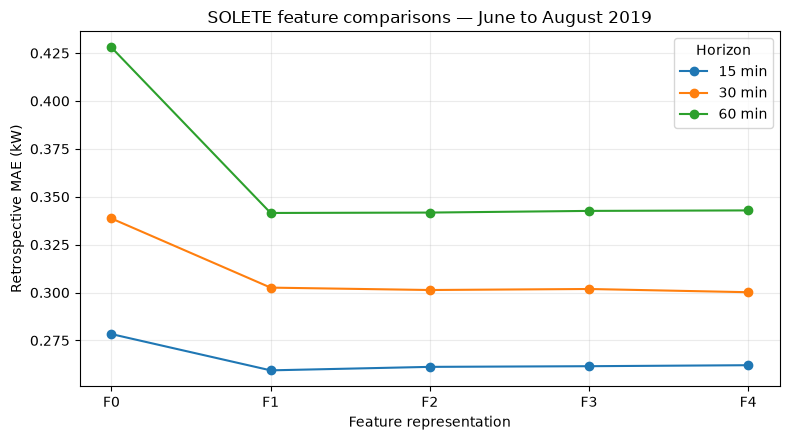

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for horizon in HORIZONS:
    ax.plot(
        ('F0', 'F1', 'F2', 'F3', 'F4'),
        [mae_table.loc[horizon, name] for name in ('F0', 'F1', 'F2', 'F3', 'F4')],
        marker='o',
        label=f'{horizon} min',
    )
ax.set_xlabel('Feature representation')
ax.set_ylabel('Retrospective MAE (kW)')
ax.set_title('SOLETE feature comparisons — June to August 2019')
ax.legend(title='Horizon')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Save the evaluation results

We save the matched predictions, model-level scores, feature contrasts, selected-model persistence comparisons, and paired intervals for the cross-dataset synthesis.

In [9]:
OUTPUT = PROJECT_ROOT / 'results' / 'solete_retrospective'
OUTPUT.mkdir(parents=True, exist_ok=True)
files = {
    'predictions': OUTPUT / 'solete_retrospective_predictions.csv.gz',
    'metrics': OUTPUT / 'solete_retrospective_metrics.csv',
    'contrasts': OUTPUT / 'solete_retrospective_feature_contrasts.csv',
    'selected_skill': OUTPUT / 'solete_retrospective_selected_model_skill.csv',
    'intervals': OUTPUT / 'solete_retrospective_intervals.csv',
}
predictions.to_csv(files['predictions'], index=False, compression='gzip', float_format='%.12g')
metrics.to_csv(files['metrics'], index=False, float_format='%.12g')
contrasts.to_csv(files['contrasts'], index=False, float_format='%.12g')
selected_skill.to_csv(files['selected_skill'], index=False, float_format='%.12g')
intervals.to_csv(files['intervals'], index=False, float_format='%.12g')

expected_lengths = {'predictions': 79_488, 'metrics': 54, 'contrasts': 30, 'selected_skill': 12, 'intervals': 42}
for name, path in files.items():
    assert path.exists() and len(pd.read_csv(path)) == expected_lengths[name]
    print(path.relative_to(PROJECT_ROOT))
print('NOTEBOOK 09: SOLETE RETROSPECTIVE EVALUATION CHECKS PASSED')

results/solete_retrospective/solete_retrospective_predictions.csv.gz
results/solete_retrospective/solete_retrospective_metrics.csv
results/solete_retrospective/solete_retrospective_feature_contrasts.csv
results/solete_retrospective/solete_retrospective_selected_model_skill.csv
results/solete_retrospective/solete_retrospective_intervals.csv
NOTEBOOK 09: SOLETE RETROSPECTIVE EVALUATION CHECKS PASSED


## Interpretation

The model and contrast tables quantify the change in forecasting error as Gregorian, solar, lunar and Panchang predictors are added. The paired intervals summarize how stable those differences are under UTC-day resampling of the fixed forecasts.

The selected-model skill table anchors the feature study to the development-selected LightGBM choices and the persistence baselines. The retrospective evaluation period had already been examined in the earlier research, so the cross-dataset replication provides the next distinct setting for assessing the generality of the representation results.